<a href="https://colab.research.google.com/github/buntyedutainer/student-performance-ai/blob/main/Notebook7_LinearRegression_Scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Upload the file into Colab
from google.colab import files
files.upload()   # pick train.csv

Saving train.csv to train.csv


{'train.csv': b'school,sex,age,address,famsize,Pstatus,Medu,Fedu,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,Mjob_health,Mjob_other,Mjob_services,Mjob_teacher,Fjob_health,Fjob_other,Fjob_services,Fjob_teacher,reason_home,reason_other,reason_reputation,guardian_mother,guardian_other,G3\n0,1,19,0,1,1,3,3,1,2,1,0,0,0,1,1,1,0,1,4,5,3,1,2,5,0,15,12,0,1,0,0,0,0,1,0,0,0,1,0,0,12\n1,0,18,1,1,1,2,3,2,1,0,0,1,1,0,1,1,1,1,5,2,3,1,2,4,0,11,10,0,0,0,0,0,0,1,0,0,0,0,0,0,10\n0,0,19,0,1,1,2,3,1,3,1,0,0,0,0,1,1,1,1,4,1,2,1,1,3,20,13,11,0,1,0,0,0,1,0,0,0,0,1,0,1,11\n0,1,15,1,1,1,4,3,1,2,0,0,1,1,1,1,1,1,0,4,3,3,2,3,5,6,9,9,0,0,0,1,0,1,0,0,1,0,0,1,0,10\n0,1,17,1,0,0,4,1,2,1,0,0,0,1,1,1,1,1,1,4,5,4,2,4,5,20,8,8,0,0,1,0,0,1,0,0,1,0,0,1,0,8\n1,0,18,1,0,1,3,1,1,2,0,0,1,1,0,1,1,1,0,4,3,4,1,1,1,0,7,9,0,0,0,1,0,0,1,0,0,0,0,1,0,8\n0,0,16,1,1,1,4,4,1,3,0,0,1,1,1,1,1,1,0,3,2,3,1,2,2,6,13,14,0,0,1,0,0,0,1,0,0,0,

In [2]:
# Cell 1: setup
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

train = pd.read_csv("train.csv")
y = train["G3"]
X_all = train.drop(columns="G3")
X_early = X_all.drop(columns=["G1", "G2"])
print("Train:", train.shape, "| features all:", X_all.shape[1], "| early:", X_early.shape[1])

Train: (285, 42) | features all: 41 | early: 39


In [4]:
# Cell 2: the building blocks, each one a few lines
def predict(X, w, b):
    return X @ w + b

def mse(y_true, y_pred):
    return np.mean((y_pred - y_true) ** 2)

def gradients(X, y_true, w, b):
    n = len(y_true)
    error = predict(X, w, b) - y_true
    dw = (2 / n) * (X.T @ error)
    db = (2 / n) * error.sum()
    return dw, db

def gradient_descent(X, y_true, lr=0.05, epochs=500):
    w = np.zeros(X.shape[1])
    b = 0.0
    history = []
    for _ in range(epochs):
        dw, db = gradients(X, y_true, w, b)
        w = w - lr * dw
        b = b - lr * db
        history.append(mse(y_true, predict(X, w, b)))
    return w, b, history

In [5]:
# Cell 3: check that the gradient formula is right, using a numerical estimate
rng = np.random.default_rng(0)
Xt = rng.normal(size=(50, 3))
yt = rng.normal(size=50)
w0, b0 = rng.normal(size=3), 0.5

dw, db = gradients(Xt, yt, w0, b0)

eps = 1e-6
dw_num = np.zeros(3)
for i in range(3):
    w_plus, w_minus = w0.copy(), w0.copy()
    w_plus[i] += eps
    w_minus[i] -= eps
    dw_num[i] = (mse(yt, predict(Xt, w_plus, b0)) - mse(yt, predict(Xt, w_minus, b0))) / (2 * eps)

print("Formula  :", dw.round(6))
print("Numerical:", dw_num.round(6))
print("Max difference:", np.abs(dw - dw_num).max())   # should be tiny, about 1e-9

Formula  : [-2.773776 -0.620164 -2.506937]
Numerical: [-2.773776 -0.620164 -2.506937]
Max difference: 5.944262859713945e-10


Learned weight (per 1 std of G2): [3.142] | bias: 11.547
Final MSE: 0.707 | RMSE: 0.841


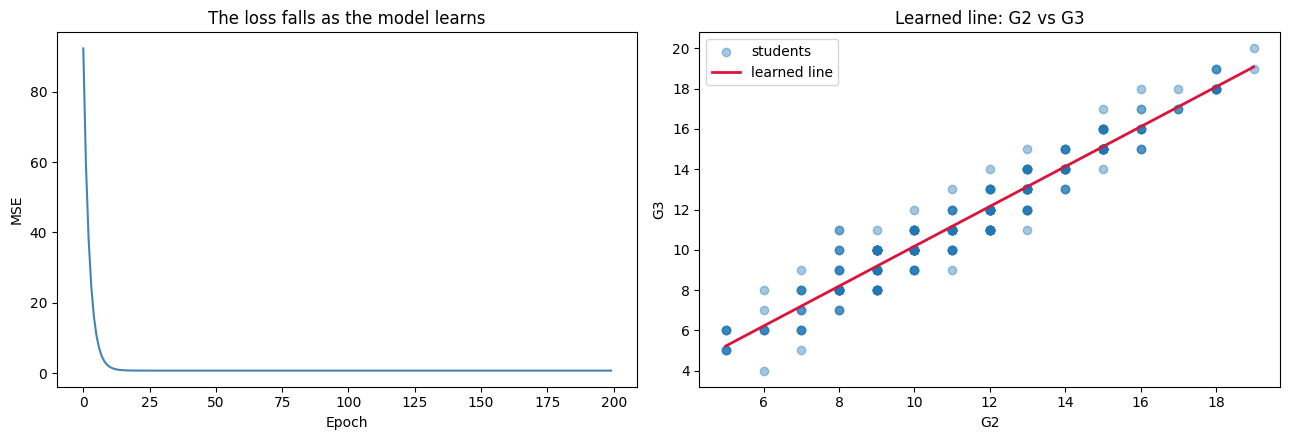

In [6]:
# Cell 4: one feature first (G2 -> G3), so you can see the line learn
x = train["G2"].values
yy = train["G3"].values

x_mean, x_std = x.mean(), x.std()
xs = ((x - x_mean) / x_std).reshape(-1, 1)      # standardised, shape (n, 1)

w, b, hist = gradient_descent(xs, yy, lr=0.1, epochs=200)
print("Learned weight (per 1 std of G2):", w.round(3), "| bias:", round(b, 3))
print("Final MSE:", round(hist[-1], 3), "| RMSE:", round(np.sqrt(hist[-1]), 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist, color="steelblue")
axes[0].set_xlabel("Epoch"); axes[0].set_ylabel("MSE")
axes[0].set_title("The loss falls as the model learns")

line_x = np.linspace(x.min(), x.max(), 100)
line_y = w[0] * (line_x - x_mean) / x_std + b
axes[1].scatter(x, yy, alpha=0.4, label="students")
axes[1].plot(line_x, line_y, color="crimson", linewidth=2, label="learned line")
axes[1].set_xlabel("G2"); axes[1].set_ylabel("G3"); axes[1].legend()
axes[1].set_title("Learned line: G2 vs G3")
plt.tight_layout()
plt.savefig("scratch_one_feature.png", dpi=150, bbox_inches="tight")
plt.show()

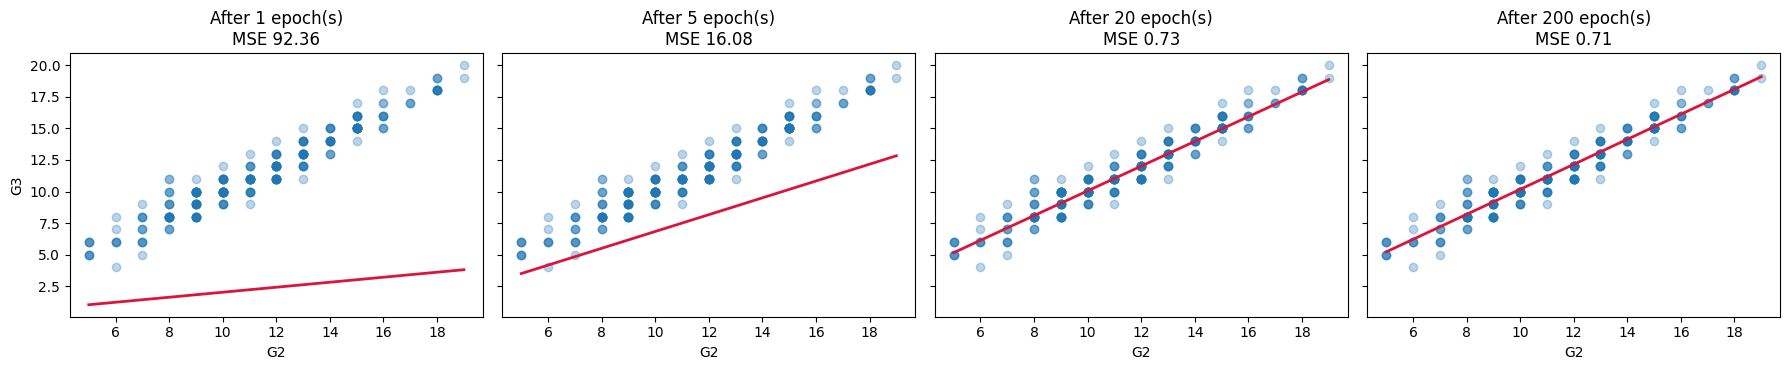

In [7]:
# Cell 5: watch the line learn, snapshots at different epochs
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8), sharey=True)
for ax, ep in zip(axes, [1, 5, 20, 200]):
    w_e, b_e, h_e = gradient_descent(xs, yy, lr=0.1, epochs=ep)
    ax.scatter(x, yy, alpha=0.3)
    ax.plot(line_x, w_e[0] * (line_x - x_mean) / x_std + b_e, color="crimson", linewidth=2)
    ax.set_title(f"After {ep} epoch(s)\nMSE {h_e[-1]:.2f}")
    ax.set_xlabel("G2")
axes[0].set_ylabel("G3")
plt.tight_layout()
plt.savefig("scratch_learning_snapshots.png", dpi=150, bbox_inches="tight")
plt.show()

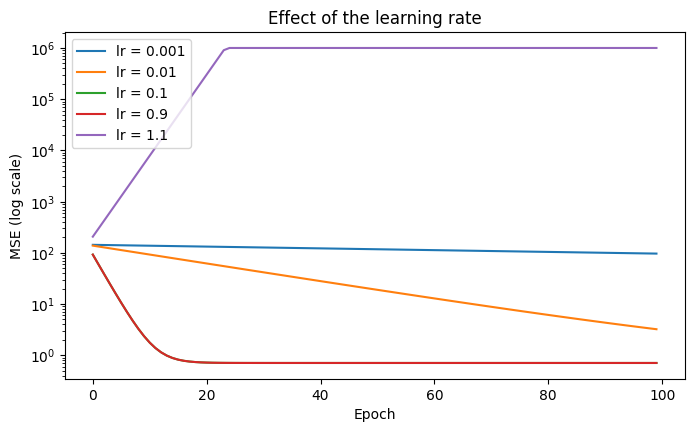

In [8]:
# Cell 6: the learning rate, too small, good, and too big
fig, ax = plt.subplots(figsize=(8, 4.5))
for lr in [0.001, 0.01, 0.1, 0.9, 1.1]:
    _, _, h = gradient_descent(xs, yy, lr=lr, epochs=100)
    h = np.minimum(h, 1e6)         # cap so diverging runs stay on the chart
    ax.plot(h, label=f"lr = {lr}")
ax.set_yscale("log")
ax.set_xlabel("Epoch"); ax.set_ylabel("MSE (log scale)")
ax.set_title("Effect of the learning rate")
ax.legend()
plt.savefig("scratch_learning_rates.png", dpi=150, bbox_inches="tight")
plt.show()

In [9]:
# Cell 7: turn it into a reusable class (scaling happens INSIDE fit, so no leakage)
class LinearRegressionScratch:
    def __init__(self, lr=0.05, epochs=3000):
        self.lr = lr
        self.epochs = epochs

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        self.mu = X.mean(axis=0)
        self.sigma = X.std(axis=0)
        self.sigma[self.sigma == 0] = 1.0           # avoid dividing by zero
        Xs = (X - self.mu) / self.sigma
        self.w, self.b, self.history = gradient_descent(Xs, y, self.lr, self.epochs)
        return self

    def predict(self, X):
        Xs = (np.asarray(X, dtype=float) - self.mu) / self.sigma
        return Xs @ self.w + self.b

def cv_rmse_scratch(X, y, **kwargs):
    kf = KFold(n_splits=5, shuffle=True, random_state=42)
    scores = []
    for tr, va in kf.split(X):
        m = LinearRegressionScratch(**kwargs).fit(X.iloc[tr], y.iloc[tr])
        scores.append(np.sqrt(mse(y.iloc[va].values, m.predict(X.iloc[va]))))
    return np.array(scores)

In [10]:
# Cell 8: cross-validated results, scratch model vs scikit-learn vs a "dumb" baseline
kf = KFold(n_splits=5, shuffle=True, random_state=42)
rows = []
for name, X in [("early (no G1/G2)", X_early), ("all features", X_all)]:
    scratch = cv_rmse_scratch(X, y, lr=0.05, epochs=3000)
    sk = -cross_val_score(make_pipeline(StandardScaler(), LinearRegression()),
                          X, y, cv=kf, scoring="neg_root_mean_squared_error")
    dummy = -cross_val_score(DummyRegressor(strategy="mean"),
                             X, y, cv=kf, scoring="neg_root_mean_squared_error")
    rows.append({"feature set": name,
                 "baseline (predict the mean)": round(dummy.mean(), 3),
                 "scikit-learn": round(sk.mean(), 3),
                 "from scratch": round(scratch.mean(), 3)})
pd.DataFrame(rows)

,feature set,baseline (predict the mean),scikit-learn,from scratch
0,early (no G1/G2),3.255,3.052,3.052
1,all features,3.255,0.906,0.906


In [11]:
# Cell 9: the normal equation, solving in one step with no loop
def normal_equation(X, y):
    Xb = np.c_[np.ones(len(X)), X]                    # add a bias column
    theta, *_ = np.linalg.lstsq(Xb, y, rcond=None)    # a stable way to solve it
    return theta[1:], theta[0]

model = LinearRegressionScratch(lr=0.05, epochs=3000).fit(X_all, y)
Xs_all = (X_all.values - model.mu) / model.sigma
w_ne, b_ne = normal_equation(Xs_all, y.values)

print("Max difference in weights, gradient descent vs normal equation:",
      np.abs(model.w - w_ne).max().round(5))
print("Bias:", round(model.b, 4), "vs", round(b_ne, 4))
print("Final training MSE:", round(model.history[-1], 4),
      "| normal equation MSE:", round(mse(y.values, Xs_all @ w_ne + b_ne), 4))

Max difference in weights, gradient descent vs normal equation: 0.0
Bias: 11.5474 vs 11.5474
Final training MSE: 0.5674 | normal equation MSE: 0.5674


G2                2.803
G1                0.376
famrel            0.158
Mjob_teacher      0.147
guardian_other   -0.126
health           -0.121
Mjob_other       -0.106
paid             -0.104
Fjob_other        0.104
goout            -0.097
dtype: float64


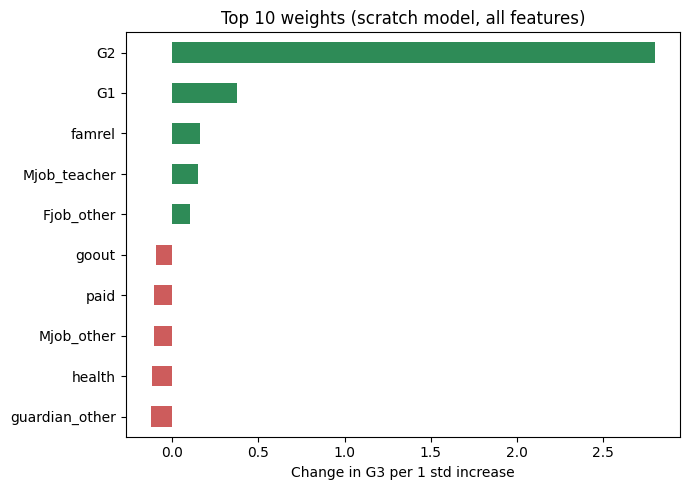

In [12]:
# Cell 10: what did the model learn? (weights are per 1 standard deviation, so comparable)
coefs = pd.Series(model.w, index=X_all.columns)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).index).head(10)
print(top.round(3))

plt.figure(figsize=(7, 5))
top.sort_values().plot(kind="barh", color=np.where(top.sort_values() > 0, "seagreen", "indianred"))
plt.title("Top 10 weights (scratch model, all features)")
plt.xlabel("Change in G3 per 1 std increase")
plt.tight_layout()
plt.savefig("scratch_weights.png", dpi=150, bbox_inches="tight")
plt.show()

In [13]:
%%writefile linreg_scratch.py
# Cell 11: save your model so later days can import it
import numpy as np

def gradient_descent(X, y, lr=0.05, epochs=3000):
    w, b, history = np.zeros(X.shape[1]), 0.0, []
    n = len(y)
    for _ in range(epochs):
        error = X @ w + b - y
        w -= lr * (2 / n) * (X.T @ error)
        b -= lr * (2 / n) * error.sum()
        history.append(np.mean(error ** 2))
    return w, b, history

class LinearRegressionScratch:
    def __init__(self, lr=0.05, epochs=3000):
        self.lr, self.epochs = lr, epochs

    def fit(self, X, y):
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.mu, self.sigma = X.mean(axis=0), X.std(axis=0)
        self.sigma[self.sigma == 0] = 1.0
        self.w, self.b, self.history = gradient_descent((X - self.mu) / self.sigma, y, self.lr, self.epochs)
        return self

    def predict(self, X):
        return ((np.asarray(X, float) - self.mu) / self.sigma) @ self.w + self.b

Writing linreg_scratch.py
